# Résultats de classification

Le SVM texte au seuil macro9 est retenu sur validation : **64,95 % de F1 macro8** et **64,46 % de macro9**. Sur test : **65,17 % et 64,81 %**.

Ce notebook relit les résultats enregistrés, sans entraîner de modèle ni charger le corpus brut ou les poids. Le test intervient aussi dans les comparaisons exploratoires : ses résultats sont descriptifs et ne constituent pas une estimation indépendante de toute l’exploration.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models/registry.json").exists())
TAGS = json.loads((ROOT / "models/registry.json").read_text(encoding="utf-8"))["target_order"]
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
LABELS = {'tfidf_svm': 'SVM texte · seuil macro9', 'word_char_svm': 'SVM mots/caractères · seuil macro8', 'tfidf_logreg': 'Logistique · seuil macro8', 'cnn_word2vec': 'CNN Word2Vec · seuil macro8', 'cnn_fasttext': 'CNN fastText · seuil macro8', 'cnn_random': 'CNN aléatoire · seuil 0,5', 'rules': 'Règles lexicales', 'none': 'Aucun tag'}


## Modèle retenu : résultats globaux

In [2]:
selection = json.loads((ROOT / "results/selection.json").read_text(encoding="utf-8"))
validation = pd.read_csv(ROOT / "results/validation/global.csv").set_index("model")
test = pd.read_csv(ROOT / "results/test/global.csv").set_index("model")
assert validation.index.tolist() == test.index.tolist()
assert selection["winner"] == "tfidf_svm"
comparison = pd.DataFrame({"F1 macro8 validation (%)": 100 * validation.f1_macro,
                           "F1 macro8 test (%)": 100 * test.f1_macro,
                           "F1 micro test (%)": 100 * test.f1_micro,
                           "FP sans cible test": test.without_target_false_positives})
metrics = ["f1_macro", "f1_macro9", "f1_micro", "f1_weighted", "f1_no_target", "exact_match"]
selected_global = pd.DataFrame({"Validation (%)": 100 * validation.loc[selection["winner"], metrics],
                                "Test (%)": 100 * test.loc[selection["winner"], metrics]})
display(selected_global.round(2))

,Validation (%),Test (%)
f1_macro,64.95,65.17
f1_macro9,64.46,64.81
f1_micro,60.28,60.44
f1_weighted,60.24,60.68
f1_no_target,60.60,61.95
exact_match,49.75,49.60


## Modèle retenu : résultats par classe sur test

In [3]:
labels = pd.read_csv(ROOT / "results/test/per_label.csv")
selected = labels[labels.model == selection["winner"]].set_index("tag").reindex(TAGS)
selected_table = selected[["support", "precision", "recall", "f1", "fp", "fn"]].copy()
selected_table[["precision", "recall", "f1"]] *= 100
selected_table = selected_table.rename(columns={"precision": "Précision (%)", "recall": "Rappel (%)", "f1": "F1 (%)"})
display(selected_table.round(2))

,support,Précision (%),Rappel (%),F1 (%),fp,fn
tag,,,,,,
math,282,49.38,70.57,58.10,204,83
graphs,108,53.66,61.11,57.14,57,42
strings,84,55.28,80.95,65.70,55,16
number theory,70,47.95,50.00,48.95,38,35
trees,65,70.31,69.23,69.77,19,20
geometry,33,63.41,78.79,70.27,15,7
games,21,100.00,66.67,80.00,0,7
probabilities,18,100.00,55.56,71.43,0,8


## Méthode et sources

Sources : `results/validation/`, `results/test/`, `results/selection.json` et `results/text_variants/`. Les variantes de texte partagent les mêmes plis du train et un objectif de seuil macro9. La logistique, le SVM mots/caractères et les CNN initialisés utilisent un objectif macro8. Les hyperparamètres sont issus d’essais exploratoires ; les scores hors pli servent au réglage.

Les deux configurations de seuil du SVM texte partagent exactement le vocabulaire, les IDF, les coefficients et les intercepts. Le CNN aléatoire utilise un checkpoint choisi par arrêt anticipé sur validation ; les CNN Word2Vec et fastText utilisent des budgets fixes. Les protocoles ne permettent donc pas d’isoler le seul effet de l’architecture ou de l’initialisation.

## Comparaison globale et compromis

In [4]:
display(comparison.rename(index=LABELS).round(2))

,F1 macro8 validation (%),F1 macro8 test (%),F1 micro test (%),FP sans cible test
model,,,,
SVM texte · seuil macro9,64.95,65.17,60.44,207
SVM mots/caractères · seuil macro8,63.45,65.61,59.54,252
Logistique · seuil macro8,60.12,60.61,57.71,216
CNN Word2Vec · seuil macro8,62.08,60.58,57.74,151
CNN fastText · seuil macro8,61.14,59.70,56.56,164
"CNN aléatoire · seuil 0,5",57.42,57.36,56.06,344
Règles lexicales,43.13,45.19,37.74,168
Aucun tag,0.00,0.00,0.00,0


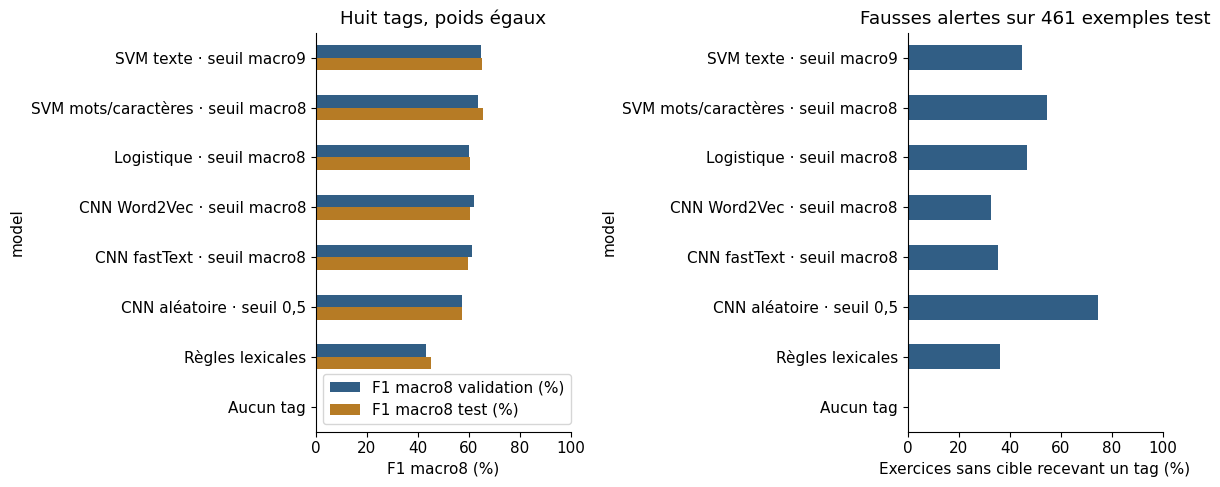

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
comparison.rename(index=LABELS)[["F1 macro8 validation (%)", "F1 macro8 test (%)"]].plot.barh(ax=axes[0], color=["#315e85", "#b67b25"])
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("F1 macro8 (%)")
axes[0].set_title("Huit tags, poids égaux")
(100 * test.without_target_false_positive_rate).rename(index=LABELS).plot.barh(ax=axes[1], color="#315e85")
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Exercices sans cible recevant un tag (%)")
axes[1].set_title("Fausses alertes sur 461 exemples test")
axes[0].invert_yaxis()
axes[1].invert_yaxis()
fig.tight_layout()
plt.show()

Le CNN Word2Vec produit moins de fausses alertes sans cible que le SVM texte. Le seuil macro9 du SVM donne toutefois de meilleurs macro8, macro9, micro et weighted que son seuil macro8.

## F1 par classe des approches comparées

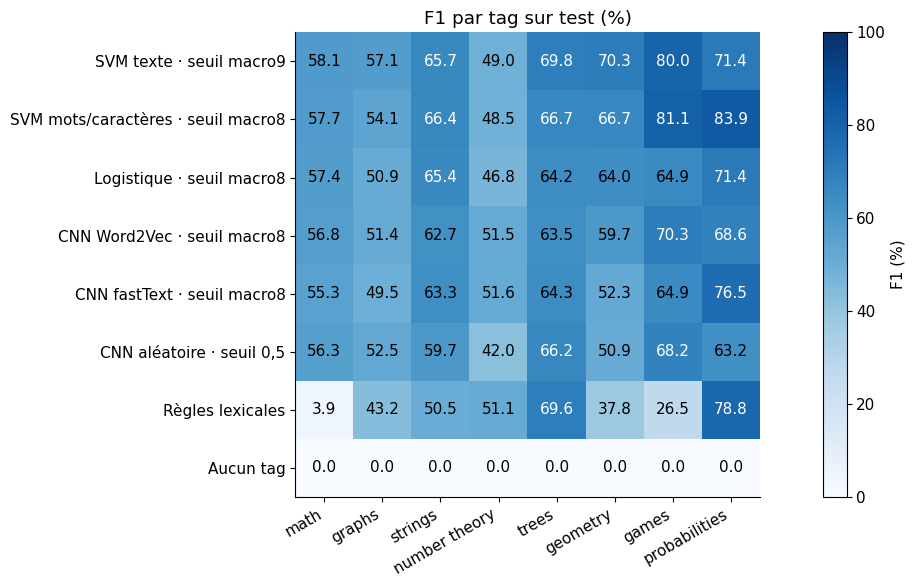

In [6]:
matrix = labels.pivot(index="model", columns="tag", values="f1").reindex(index=test.index, columns=TAGS)
fig, ax = plt.subplots(figsize=(13, 6))
image = ax.imshow(100 * matrix.to_numpy(), vmin=0, vmax=100, cmap="Blues")
ax.set_xticks(range(8), TAGS, rotation=30, ha="right")
ax.set_yticks(range(len(matrix)), [LABELS[name] for name in matrix.index])
for (i, j), value in np.ndenumerate(matrix.to_numpy()):
    ax.text(j, i, f"{100 * value:.1f}", ha="center", va="center", color="white" if value > .65 else "black")
ax.set_title("F1 par tag sur test (%)")
fig.colorbar(image, ax=ax, label="F1 (%)")
fig.tight_layout()
plt.show()

Avec le seuil macro9 plutôt que macro8, sept F1 de classe augmentent sur test. `probabilities` diminue de 80,00 % à 71,43 %, avec dix positifs retrouvés contre douze sur un support de dix-huit. La précision de 100 % sur `games` et `probabilities` ne signifie pas un rappel parfait.

## État sans cible et macro9

L’état vide est dérivé de l’absence de tous les tags, sans neuvième sortie apprise. Macro9 est l’objectif de seuil et de sélection des variantes de texte. Pour les approches réglées sur macro8, macro9 reste une métrique descriptive.

In [7]:
display((100 * test.rename(index=LABELS)[["f1_macro", "f1_no_target", "f1_macro9", "exact_match"]]).round(2))
assert np.allclose(test.f1_macro9, (8 * test.f1_macro + test.f1_no_target) / 9)

,f1_macro,f1_no_target,f1_macro9,exact_match
model,,,,
SVM texte · seuil macro9,65.17,61.95,64.81,49.60
SVM mots/caractères · seuil macro8,65.61,56.41,64.59,44.82
Logistique · seuil macro8,60.61,60.20,60.57,47.71
CNN Word2Vec · seuil macro8,60.58,67.46,61.34,50.80
CNN fastText · seuil macro8,59.70,64.50,60.24,51.89
"CNN aléatoire · seuil 0,5",57.36,37.26,55.13,38.35
Règles lexicales,45.19,60.16,46.85,40.14
Aucun tag,0.00,62.94,6.99,45.92


## Effet des seuils sur validation

In [8]:
thresholds = pd.read_csv(ROOT / "results/validation/threshold_variants.csv")
display(thresholds.loc[thresholds.model == "tfidf_svm",
                       ["threshold_mode", "f1_macro", "precision_macro", "recall_macro", "without_target_false_positives"]].round(4))
pairs = pd.DataFrame(json.loads((ROOT / "results/validation/paired_bootstrap.json").read_text(encoding="utf-8")))
display(pairs.loc[(pairs.left == "tfidf_svm") & (pairs.right == "word_char_svm"),
                  ["left", "right", "delta_f1_macro", "ci_low", "ci_high"]].round(4))

,threshold_mode,f1_macro,precision_macro,recall_macro,without_target_false_positives
9,natural,0.6094,0.7239,0.5479,136
10,global_macro8,0.6370,0.5832,0.7267,278
11,per_tag,0.6292,0.5902,0.6852,209
15,global_macro9,0.6495,0.6322,0.6835,218


,left,right,delta_f1_macro,ci_low,ci_high
4,tfidf_svm,word_char_svm,0.015,-0.0076,0.037


Les seuils globaux macro8 et macro9 sont distingués dans le tableau. Les intervalles appariés restent descriptifs et ne corrigent pas le biais de sélection lié aux essais exploratoires.

## Apprentissage des CNN initialisés

Budgets fixes, sans arrêt sur validation : 22 époques Word2Vec, 29 fastText. Les losses ci-dessous sont les moyennes des mini-batches en mode entraînement, avec dropout et pondération des classes. Elles ne sont pas des losses de validation.

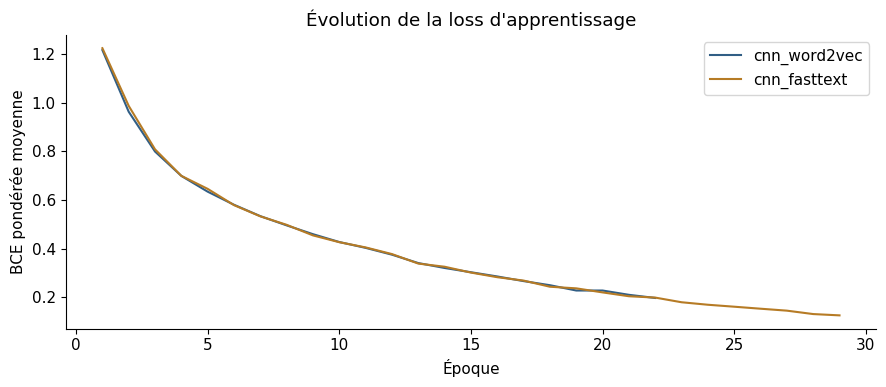

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, color in [("cnn_word2vec", "#315e85"), ("cnn_fasttext", "#b67b25")]:
    history = pd.DataFrame(json.loads((ROOT / f"results/training/{name}.json").read_text(encoding="utf-8")))
    ax.plot(history.step, history.train_loss, label=name, color=color)
ax.set_xlabel("Époque")
ax.set_ylabel("BCE pondérée moyenne")
ax.set_title("Évolution de la loss d'apprentissage")
ax.legend()
fig.tight_layout()
plt.show()

## Caractéristiques de texte et objectifs de seuil

Les résultats portent sur la même validation. Le SVM standard au seuil macro9 obtient le meilleur macro8 et macro9 des variantes comparées. Les règles aident `number theory` et les sorties vides ; le filtrage lexical aide `trees`, sans meilleur résultat global.

`reference_tfidf_svm` désigne le SVM au seuil macro8. Son registre `models/reference_macro8.json` réutilise les mêmes poids que le seuil macro9. Le test ne détermine ni la sélection ni le seuil.

In [10]:
variants = pd.read_csv(ROOT / "results/text_variants/global.csv").set_index("model")
display((100 * variants.rename(index={"reference_tfidf_svm": "SVM texte · seuil macro8", "tfidf_svm": "SVM texte · seuil macro9", "tfidf_manual_rules": "SVM + règles · seuil macro9", "tfidf_stopwords": "SVM + filtrage · seuil macro9"})[["f1_macro", "f1_macro9", "f1_micro", "f1_no_target"]]).round(2))
assert variants.f1_macro9.idxmax() == selection["winner"]
parameter_check = json.loads((ROOT / "results/text_variants/parameter_check.json").read_text(encoding="utf-8"))
assert parameter_check["coefficients_equal_for_all_eight_tags"]
assert parameter_check["idf_equal"]
assert parameter_check["oof_scores_equal"]

,f1_macro,f1_macro9,f1_micro,f1_no_target
model,,,,
SVM texte · seuil macro9,64.95,64.46,60.28,60.60
SVM texte · seuil macro8,63.70,62.38,59.27,51.84
SVM + règles · seuil macro9,63.76,63.97,59.24,65.59
SVM + filtrage · seuil macro9,63.33,62.92,59.80,59.60
